# WP04 · Moleküler veri keşfi ve RDKit

**Öğren → Gerçek yapı → Tablo → Görsel → QC.** Onaylı 62 DrugBank ana ID incelenir. SIDER yalnız önceki kohort tanımıdır; PT, kategori ve etiket sayıları kimyasal hesaplara girmez. Bu notebook kayıtlı WP04 yapı alanlarını okur; XML'i yeniden taramaz, internet/API veya eğitim başlatmaz.

SMILES bir molekülün atomlarını, bağlarını, dallarını ve halka kapanışlarını metinle anlatır. `C/N/O` atom simgeleri, `=` çift bağ, küçük `c/n` aromatik atom, nokta `.` bağlantısız bileşen, `@/@@` yerel tetrahedral stereokimya, `/` ve `\` bağ geometrisi için işaretlerdir. `@` tek başına R, `@@` tek başına S demek değildir; yazımdaki komşu sırası önemlidir. Sayılar atom sayısı değil halka kapatma etiketleridir.

In [1]:
from pathlib import Path
import sys,json,pandas as pd,numpy as np
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'AGENTS.md').exists())
sys.path.insert(0,str(ROOT/'scripts'))
from wp04_chemistry import parse_smiles,identity,descriptors,atom_bond_tables,Chem,rdBase
from rdkit.Chem import Draw,rdDepictor
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display,Image
pd.set_option('display.max_rows',100);pd.set_option('display.max_colwidth',130)
QA=ROOT/'reports/qa/WP04';FIG=ROOT/'reports/figures/WP04';FIG.mkdir(parents=True,exist_ok=True)
def read(n):return pd.read_csv(QA/n,keep_default_na=False)
sources=read('structure_sources.csv');qc=read('structure_validation.csv')
raw=pd.read_csv(QA/'chemical_features_raw.csv');clean=pd.read_csv(QA/'chemical_features_clean.csv')
recovery=read('coverage_and_recovery.csv');summary=json.loads((QA/'coverage_summary.json').read_text(encoding='utf-8'))
mols={r.id:parse_smiles(r.raw_smiles)[0] for r in sources.itertuples()}
display(pd.DataFrame([{'Python':sys.version.split()[0],'RDKit':rdBase.rdkitVersion,'ilaç':len(sources),'ağ çağrısı':summary['pubchem_requests_this_analysis']}]))

,Python,RDKit,ilaç,ağ çağrısı
0,3.11.3,2026.09.1,62,0


## 1. Önce mevcut kaynak ve gerçek XML alanları

DrugBank XML `drug/calculated-properties/property` altında `kind/value/source` üçlüleri vardır. Molekül ağırlığı ve H-bağı alanları da yereldedir; eski kodda “XML'den çekilemedi” denmesi bu alanların hiç bulunmadığı anlamına gelmiyordu. **CID köprüsü yapı dosyası değildir:** önceki gerçek `drug links.csv` şeması CID/SID içerir, SMILES/InChI içermez. WP02 köprü anlık görüntüsüyle kimlik bağı korunur. Tuz listesi ana ilacın alternatif tuz kayıtlarına bağlanır; SMILES'in mutlaka tuz içerdiğini göstermez.

In [2]:
fields=read('xml_field_coverage.csv');display(fields[fields.kind.isin(['SMILES','InChI','InChIKey','Molecular Formula','Molecular Weight','H Bond Donor Count','H Bond Acceptor Count','logP','Polar Surface Area (PSA)'])])
manifest=json.loads((QA/'xml_extract_manifest.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{k:manifest[k] for k in ['records_scanned','selected_found','bytes_read','elapsed_seconds','sampled_rss_max_mib','os_peak_wset_mib','metadata_unchanged']}]))
evidence=read('xml_property_evidence.csv')
display(evidence[evidence.id.eq('DB00601') & evidence.kind.isin(['SMILES','InChI','InChIKey','logP','Molecular Weight'])][['section','kind','value','source']])

,kind,property_rows,drugs_with_field
0,logP,177,62
5,Molecular Weight,62,62
7,SMILES,62,62
8,Molecular Formula,62,62
9,InChI,62,62
10,InChIKey,62,62
11,Polar Surface Area (PSA),62,62
15,H Bond Acceptor Count,62,62
16,H Bond Donor Count,62,62


,records_scanned,selected_found,bytes_read,elapsed_seconds,sampled_rss_max_mib,os_peak_wset_mib,metadata_unchanged
0,6014,62,1186480128,101.969,74.476562,394.941406,True


,section,kind,value,source
675,calculated-properties,logP,0.61,ALOGPS
678,calculated-properties,logP,0.64,ChemAxon
681,calculated-properties,Molecular Weight,337.3461,ChemAxon
683,calculated-properties,SMILES,CC(=O)NC[C@H]1CN(C(=O)O1)C1=CC(F)=C(C=C1)N1CCOCC1,ChemAxon
685,calculated-properties,InChI,"InChI=1S/C16H20FN3O4/c1-11(21)18-9-13-10-20(16(22)24-13)12-2-3-15(14(17)8-12)19-4-6-23-7-5-19/h2-3,8,13H,4-7,9-10H2,1H3,(H,18,...",ChemAxon
686,calculated-properties,InChIKey,TYZROVQLWOKYKF-ZDUSSCGKSA-N,ChemAxon
703,experimental-properties,logP,0.9,


**Yorum:** 62/62 kayıtta üç yapı alanı var. Son seçili ana kayıtta duruldu; dosyanın tümü belleğe alınmadı. Aynı `logP` adı altında farklı hesaplayıcılar/deneysel değerler bulunabilir; bu satırlar ortalanmadı veya son satırla ezilmedi. XML dışa aktarımında kök sürüm `5.1`, tarih `2026-01-04`; daha ayrıntılı DrugBank sürümü çıkarılamaz.

## 2. Canonical/isomeric SMILES ve InChI kimliği

Canonical SMILES belirli bir yazılım ve sürümün atom sıralama kuralına göre üretilir; evrensel tek dize değildir. “Canonical” olması stereo taşımadığı anlamına gelmez. RDKit `canonical=True, isomericSmiles=True` ikisini birlikte kullanabilir. Buradaki nonisomeric çıktı stereo/isotop ayrıntısını dışarıda bırakır; kaynak yapı yerine kullanılmaz.

InChI katmanlı bir yapı tanımıdır; InChIKey bunun özetidir ve tek başına molekülü geri kurmaya yetmez. Tam anahtar uyumu yerel kaynak içi tutarlılıktır; bağımsız klinik/formülasyon eşdeğerliği veya güncel PubChem yapısı doğrulaması değildir. İlk InChIKey bloğunun aynı olması stereo/protonasyon/diğer katmanların tümünün aynı olduğu anlamına gelmez.

In [3]:
ids=['DB00601','DB01137','DB01165']
display(sources[sources.id.isin(ids)][['id','name','cid','raw_smiles','raw_inchi','raw_inchikey']])
display(qc[qc.id.isin(ids)][['id','name','rdkit_isomeric_smiles','rdkit_nonisomeric_smiles','chiral_assigned','chiral_unassigned','smiles_key_relation']])
levo=qc.set_index('id').loc['DB01137'];oflo=qc.set_index('id').loc['DB01165']
display(pd.DataFrame([{'gerçek örnek':'Levofloxacin / Ofloxacin','nonisomeric_yazım_eşit':levo.rdkit_nonisomeric_smiles==oflo.rdkit_nonisomeric_smiles,'tam_InChIKey_eşit':levo.rdkit_inchikey==oflo.rdkit_inchikey}]))

,id,name,cid,raw_smiles,raw_inchi,raw_inchikey
23,DB00601,Linezolid,441401,CC(=O)NC[C@H]1CN(C(=O)O1)C1=CC(F)=C(C=C1)N1CCOCC1,"InChI=1S/C16H20FN3O4/c1-11(21)18-9-13-10-20(16(22)24-13)12-2-3-15(14(17)8-12)19-4-6-23-7-5-19/h2-3,8,13H,4-7,9-10H2,1H3,(H,18,...",TYZROVQLWOKYKF-ZDUSSCGKSA-N
44,DB01137,Levofloxacin,149096,C[C@H]1COC2=C3N1C=C(C(O)=O)C(=O)C3=CC(F)=C2N1CCN(C)CC1,"InChI=1S/C18H20FN3O4/c1-10-9-26-17-14-11(16(23)12(18(24)25)8-22(10)14)7-13(19)15(17)21-5-3-20(2)4-6-21/h7-8,10H,3-6,9H2,1-2H3,...",GSDSWSVVBLHKDQ-JTQLQIEISA-N
47,DB01165,Ofloxacin,4583,CC1COC2=C3N1C=C(C(O)=O)C(=O)C3=CC(F)=C2N1CCN(C)CC1,"InChI=1S/C18H20FN3O4/c1-10-9-26-17-14-11(16(23)12(18(24)25)8-22(10)14)7-13(19)15(17)21-5-3-20(2)4-6-21/h7-8,10H,3-6,9H2,1-2H3,...",GSDSWSVVBLHKDQ-UHFFFAOYSA-N


,id,name,rdkit_isomeric_smiles,rdkit_nonisomeric_smiles,chiral_assigned,chiral_unassigned,smiles_key_relation
23,DB00601,Linezolid,CC(=O)NC[C@H]1CN(c2ccc(N3CCOCC3)c(F)c2)C(=O)O1,CC(=O)NCC1CN(c2ccc(N3CCOCC3)c(F)c2)C(=O)O1,1,0,full_inchikey_match
44,DB01137,Levofloxacin,C[C@H]1COc2c(N3CCN(C)CC3)c(F)cc3c(=O)c(C(=O)O)cn1c23,CC1COc2c(N3CCN(C)CC3)c(F)cc3c(=O)c(C(=O)O)cn1c23,1,0,full_inchikey_match
47,DB01165,Ofloxacin,CC1COc2c(N3CCN(C)CC3)c(F)cc3c(=O)c(C(=O)O)cn1c23,CC1COc2c(N3CCN(C)CC3)c(F)cc3c(=O)c(C(=O)O)cn1c23,0,1,full_inchikey_match


,gerçek örnek,nonisomeric_yazım_eşit,tam_InChIKey_eşit
0,Levofloxacin / Ofloxacin,True,False


**Yorum:** Aynı bağlantı yapısına sahip yazımlar stereo ayrıntısında ayrışabilir. Ofloxacin kaydında stereo işareti yokluğunu rastgele bir enantiyomer seçerek tamamlamıyoruz. Kaynak anahtarının eşleşmesi, belirtilmemiş stereonun otomatik tamamlandığı anlamına gelmez.

## 3. Tüm 62 ilaç için yapı kapsamı

Yapılar doğrudan yerel XML ana ID kaydından gelir; CID hem XML hem mevcut köprüyle eşleşir. `strict_qc_pass` bu WP'deki temkinli inceleme politikasıdır, nihai model kohortu değildir. Bir bayrak SMILES'in ayrıştırılamadığı anlamına gelmez. Kaynak InChI'den hesaplanan anahtar da ayrı kontrol edildi.

,id,name,cid,parse_status,identity_verified_local,strict_qc_pass,review_flags,old_chemistry_available
0,DB00199,Erythromycin,12560,valid,True,True,,True
1,DB00207,Azithromycin,447043,valid,True,True,,True
2,DB00254,Doxycycline,54671203,valid,True,True,,True
3,DB00259,Sulfanilamide,5333,valid,True,True,,True
4,DB00301,Flucloxacillin,21319,valid,True,True,,True
5,DB00303,Ertapenem,150610,valid,True,True,,True
6,DB00319,Piperacillin,43672,valid,True,True,,True
7,DB00359,Sulfadiazine,5215,valid,True,True,,True
8,DB00415,Ampicillin,6249,valid,True,True,,True
9,DB00417,Phenoxymethylpenicillin,6869,valid,True,True,,True


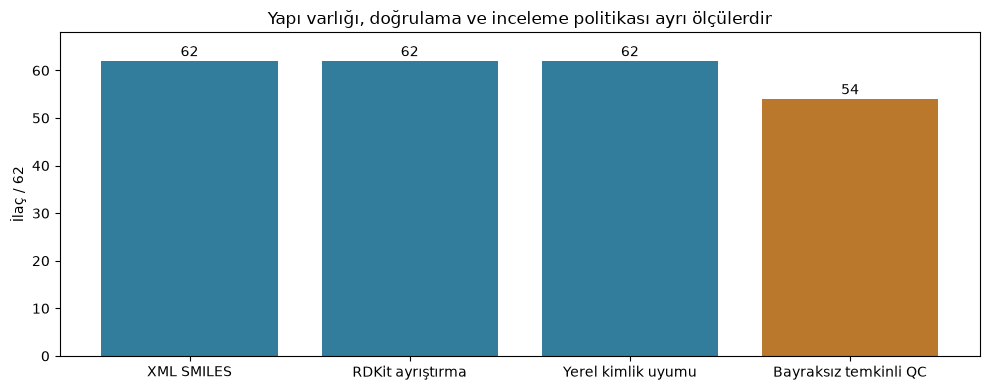

In [4]:
table=qc[['id','name','cid','parse_status','identity_verified_local','strict_qc_pass','review_flags']].merge(recovery[['id','old_chemistry_available']],on='id',validate='one_to_one')
display(table)
fig,ax=plt.subplots(figsize=(10,4));labels=['XML SMILES','RDKit ayrıştırma','Yerel kimlik uyumu','Bayraksız temkinli QC'];vals=[summary[k] for k in ['xml_structures','valid_smiles','local_identity_verified','strict_qc_pass']]
ax.bar(labels,vals,color=['#327d9b','#327d9b','#327d9b','#b9782c']);ax.set_ylim(0,68);ax.set_ylabel('İlaç / 62')
for i,v in enumerate(vals):ax.text(i,v+1,str(v),ha='center')
ax.set_title('Yapı varlığı, doğrulama ve inceleme politikası ayrı ölçülerdir');plt.tight_layout();plt.savefig(FIG/'01_structure_coverage.png',dpi=160);plt.show()

**Yorum:** Üç ilk basamak 62; bayraksız temkinli QC 54. Bu 8 kaydı biyolojik olarak yanlış veya kullanılamaz ilan etmiyoruz. Özellikle stereokimya belirsizliği ile çok bileşenlilik farklı inceleme nedenleridir. Yeni yapı sorgusu yapılmadan 62 yapı üzerinde hesap yapılabiliyor.

## 4. Başarısız ayrıştırma, tuz, karışım, metal ve stereo kontrolü

Kaynakta ayrıştırma hatası, yerel tam InChIKey uyuşmazlığı ve metal atomu bulunmadı; sıfır gözlenmesi bu problemlerin genel olarak imkânsız olduğu anlamına gelmez. Tuz bağlantısı olan ana kayıt ve noktayla ayrılmış SMILES bileşenleri farklı şeylerdir. Gentamicin kaydındaki üç bileşeni tek bir “en büyük fragment” seçerek değiştirmiyoruz.

,id,name,components,metal_atoms,chiral_unassigned,legacy_chiral_unassigned,double_stereo_unassigned,review_flags
21,DB00578,Carbenicillin,1,,1,1,0,unspecified_atom_stereo
31,DB00798,Gentamicin,3,,2,2,0,multiple_components|unspecified_atom_stereo
37,DB00978,Lomefloxacin,1,,1,1,0,unspecified_atom_stereo
39,DB01044,Gatifloxacin,1,,1,1,0,unspecified_atom_stereo
45,DB01150,Cefprozil,1,,0,0,1,unspecified_double_bond_stereo
46,DB01155,Gemifloxacin,1,,1,1,0,unspecified_atom_stereo
47,DB01165,Ofloxacin,1,,1,1,0,unspecified_atom_stereo
61,DB06799,Methenamine,1,,4,0,0,unspecified_atom_stereo


,id,name,declared_salt_links
0,DB00199,Erythromycin,8
1,DB00207,Azithromycin,3
2,DB00254,Doxycycline,4
4,DB00301,Flucloxacillin,1
5,DB00303,Ertapenem,1
6,DB00319,Piperacillin,1
7,DB00359,Sulfadiazine,1
8,DB00415,Ampicillin,2
9,DB00417,Phenoxymethylpenicillin,2
10,DB00438,Ceftazidime,2


,ayrıştırma_hatası,yerel_anahtar_uyuşmazlığı,metal_içeren,çok_bileşenli
0,0,0,0,1


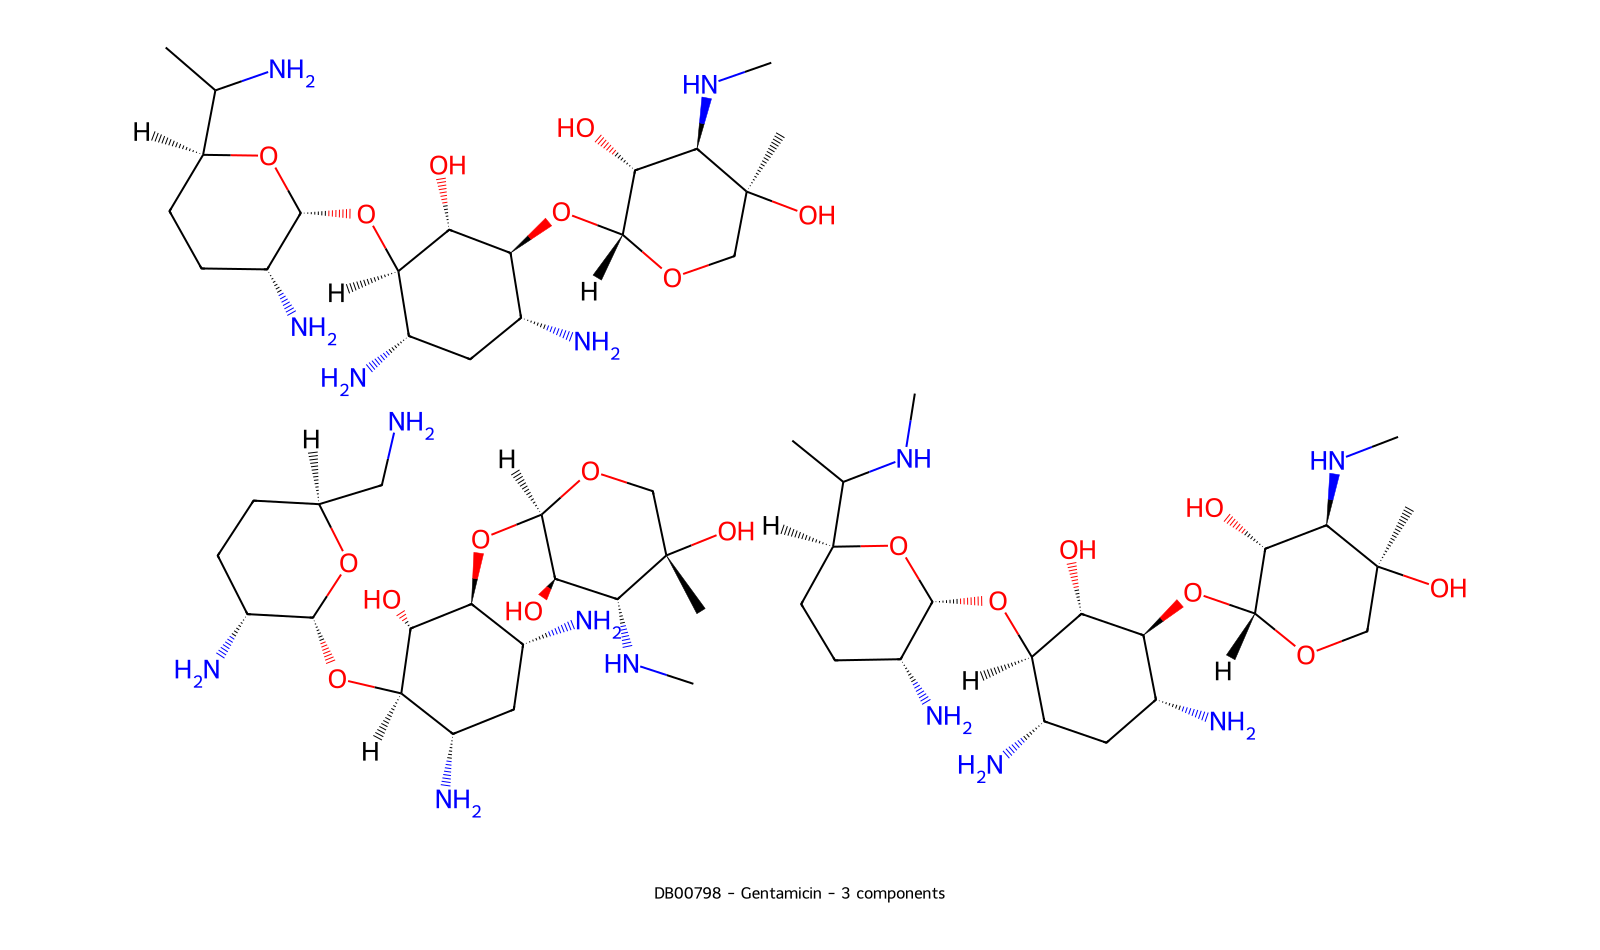

In [5]:
flagged=qc[qc.review_flags.ne('')];display(flagged[['id','name','components','metal_atoms','chiral_unassigned','legacy_chiral_unassigned','double_stereo_unassigned','review_flags']])
display(sources[sources.declared_salt_links.astype(int)>0][['id','name','declared_salt_links']])
display(pd.DataFrame([{'ayrıştırma_hatası':int(qc.parse_status.ne('valid').sum()),'yerel_anahtar_uyuşmazlığı':int(qc.smiles_key_relation.ne('full_inchikey_match').sum()),'metal_içeren':int(qc.metal_atoms.ne('').sum()),'çok_bileşenli':int(qc.components.astype(int).gt(1).sum())}]))
gm=Chem.Mol(mols['DB00798']);before=(gm.GetNumAtoms(),gm.GetNumBonds())
img=Draw.MolToImage(gm,size=(1600,950),legend='DB00798 - Gentamicin - 3 components');img.save(FIG/'02_gentamicin_components.png');display(img)
assert before==(gm.GetNumAtoms(),gm.GetNumBonds())

**Yorum:** Gentamicin kaydı C60H123N15O21 formülüyle üç ayrı organik bileşen taşıyor. Ham özellikler bu tam kayıt için hesaplanır; tek bir gentamicin bileşeninin ya da ticari bir karışımın derişim ağırlıklı özelliği değildir. “Nokta varsa tuzdur” denemez. Methenamine'de yeni RDKit stereo algılayıcısı 4 potansiyel N merkezi işaretliyor, eski algılayıcı 0; bu algoritma farkı gerçek stereo hatası diye sunulmuyor. Cefprozil'de bir çift bağ geometrisi belirtilmemiş. Sekiz kayıt temiz tabloda bekletiliyor; kaynak değerleri korunuyor.

## 5. Beş tanımlayıcı nasıl hesaplanıyor?

| Alan | WP04 tanımı | Birim / sınır |
|---|---|---|
| MW | RDKit `Descriptors.MolWt` | g/mol, ortalama molekül ağırlığı; monoisotopik/ExactMolWt değil |
| LogP | Wildman–Crippen `Crippen.MolLogP` | boyutsuz hesap; eski PubChem XLogP ile aynı yöntem değil, deneysel logD değil |
| HBD | `Lipinski.NumHDonors` | donor merkez sayısı; H atomlarının toplamı değil |
| HBA | `Lipinski.NumHAcceptors` | acceptor merkez sayısı; tüm N+O atom sayısı değil |
| TPSA | `CalcTPSA(includeSandP=False)` | Å², N/O katkıları; S/P duyarlılık hesabı ayrı |

Kaynak molekülün tamamı kullanılır. Nötralizasyon, tautomer değiştirme, fragment seçme, atom/bağ silme yok. Sayısal sıfır geçerli bir sonuç olabilir; eksik değer `NaN/null` ile korunur. Hiçbir PT/kategori alanı fonksiyon parametresi değildir.

In [6]:
computed=pd.DataFrame([{'id':i,**descriptors(mols[i])} for i in ['DB01060','DB00537','DB00207']]);display(computed)
display(read('missingness.csv'));display(raw.head(8));display(clean[clean.MW.isna()])
assert list(raw.columns)==['id','MW','LogP','HBD','HBA','TPSA']
assert list(clean.columns)==list(raw.columns)

,id,MW,LogP,HBD,HBA,TPSA
0,DB01060,365.411,0.0237,4,6,132.96
1,DB00537,331.347,1.5833,2,4,74.57
2,DB00207,748.996,1.9007,5,14,180.08


,feature,cohort,old_missing,raw_missing,clean_missing_or_held
0,MW,62,21,0,8
1,LogP,62,21,0,8
2,HBD,62,21,0,8
3,HBA,62,21,0,8
4,TPSA,62,21,0,8


,id,MW,LogP,HBD,HBA,TPSA
0,DB00199,733.937,1.78560,5,14,193.91
1,DB00207,748.996,1.90070,5,14,180.08
2,DB00254,444.440,-0.34760,6,9,181.62
3,DB00259,172.209,-0.08380,2,3,86.18
4,DB00301,453.879,2.68782,2,6,112.74
5,DB00303,475.523,0.94070,5,7,156.27
6,DB00319,517.564,-0.24030,3,7,156.43
7,DB00359,250.283,0.85960,2,5,97.97


,id,MW,LogP,HBD,HBA,TPSA
21,DB00578,NaN,NaN,NaN,NaN,NaN
31,DB00798,NaN,NaN,NaN,NaN,NaN
37,DB00978,NaN,NaN,NaN,NaN,NaN
39,DB01044,NaN,NaN,NaN,NaN,NaN
45,DB01150,NaN,NaN,NaN,NaN,NaN
46,DB01155,NaN,NaN,NaN,NaN,NaN
47,DB01165,NaN,NaN,NaN,NaN,NaN
61,DB06799,NaN,NaN,NaN,NaN,NaN


**Yorum:** Ham hesap tablosunda 62 ilaçta beş değer var; temiz tabloda sekiz inceleme kaydının beş değeri de bilerek boş. Bu, hesaplanamayan molekül ile hesaplanıp incelemede tutulan molekülü ayırır. Temiz tablo eğitim tensörü değildir; veri ölçeklenmedi, doldurulmadı.

## 6. Eski V5 ile fark ve hesap yöntemi

Eski kod kaynakta PubChem MolecularWeight/XLogP/HBondDonorCount/HBondAcceptorCount/TPSA istiyordu. İzinli Drive tablosundan yalnız ham beş alan, ID, ad ve CID karşılaştırma için alındı; eski normalizasyonlar kullanılmadı. 41 ortak kaydın CID'si mevcut kohort CID'siyle uyumlu. LogP yöntem farkı doğrudan hesap hatası değildir.

,feature,comparable_drugs,mean_absolute_difference,median_signed_difference,max_absolute_difference,exact_numeric_matches
0,HBA,41,1.317073,-1.0000,5.0000,15
1,HBD,41,0.000000,0.0000,0.0000,41
2,LogP,41,1.133578,0.4236,2.7062,0
3,MW,41,0.016244,0.0030,0.0710,1
4,TPSA,41,8.574146,-0.3900,33.9400,0


,id,name,feature,old_value,rdkit_value,delta_rdkit_minus_old,legacy_cid,cid_agrees,strict_qc_pass,definition_note,abs_delta
299,DB06211,Doripenem,TPSA,196.0,162.06,-33.94,73303.0,True,True,legacy PubChem TPSA vs RDKit N/O-only; S/P sensitivity separately,33.94
29,DB00303,Ertapenem,TPSA,182.0,156.27,-25.73,150610.0,True,True,legacy PubChem TPSA vs RDKit N/O-only; S/P sensitivity separately,25.73
34,DB00319,Piperacillin,TPSA,182.0,156.43,-25.57,43672.0,True,True,legacy PubChem TPSA vs RDKit N/O-only; S/P sensitivity separately,25.57
204,DB01053,Benzylpenicillin,TPSA,112.0,86.71,-25.29,5904.0,True,True,legacy PubChem TPSA vs RDKit N/O-only; S/P sensitivity separately,25.29
44,DB00415,Ampicillin,TPSA,138.0,112.73,-25.27,6249.0,True,True,legacy PubChem TPSA vs RDKit N/O-only; S/P sensitivity separately,25.27
24,DB00301,Flucloxacillin,TPSA,138.0,112.74,-25.26,21319.0,True,True,legacy PubChem TPSA vs RDKit N/O-only; S/P sensitivity separately,25.26
74,DB00485,Dicloxacillin,TPSA,138.0,112.74,-25.26,18381.0,True,True,legacy PubChem TPSA vs RDKit N/O-only; S/P sensitivity separately,25.26
49,DB00417,Phenoxymethylpenicillin,TPSA,121.0,95.94,-25.06,6869.0,True,True,legacy PubChem TPSA vs RDKit N/O-only; S/P sensitivity separately,25.06
124,DB00607,Nafcillin,TPSA,121.0,95.94,-25.06,8982.0,True,True,legacy PubChem TPSA vs RDKit N/O-only; S/P sensitivity separately,25.06
214,DB01060,Amoxicillin,TPSA,158.0,132.96,-25.04,33613.0,True,True,legacy PubChem TPSA vs RDKit N/O-only; S/P sensitivity separately,25.04


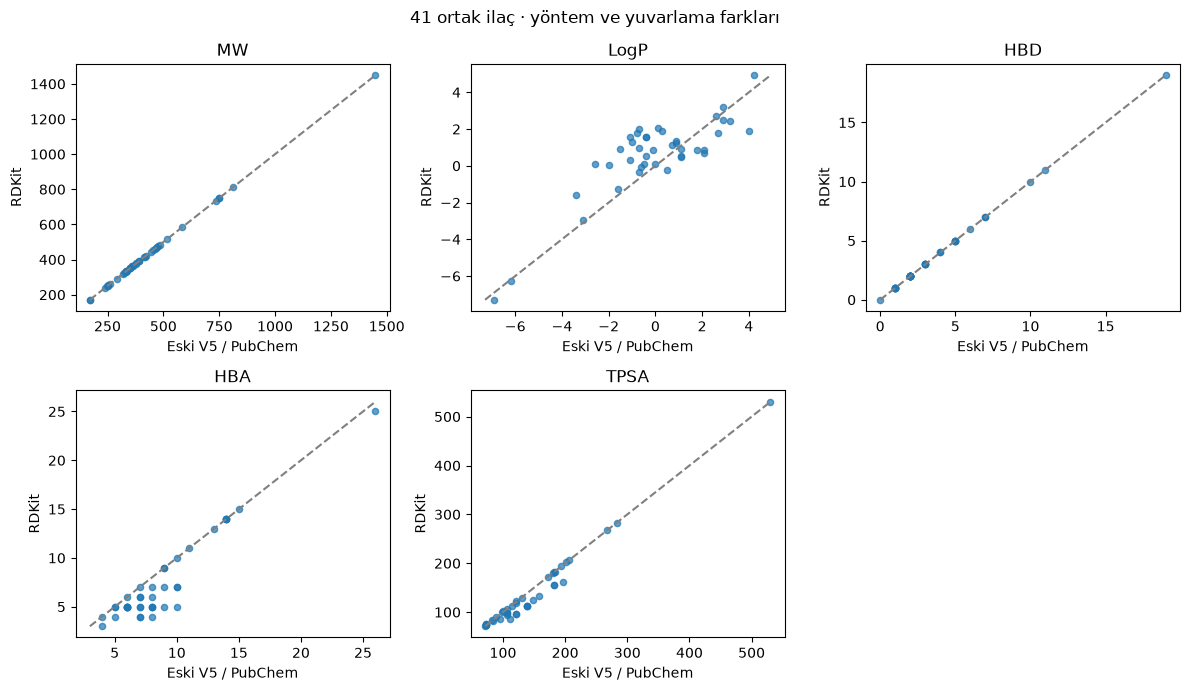

In [7]:
diff=pd.read_csv(QA/'legacy_feature_comparison.csv');display(read('legacy_difference_summary.csv'))
display(diff[diff.old_value.notna()].assign(abs_delta=lambda d:d.delta_rdkit_minus_old.abs()).sort_values('abs_delta',ascending=False).head(15))
fig,axes=plt.subplots(2,3,figsize=(12,7))
for ax,k in zip(axes.flat,['MW','LogP','HBD','HBA','TPSA']):
    d=diff[diff.feature.eq(k)&diff.old_value.notna()];ax.scatter(d.old_value,d.rdkit_value,s=20,alpha=.7)
    lo=min(d.old_value.min(),d.rdkit_value.min());hi=max(d.old_value.max(),d.rdkit_value.max());ax.plot([lo,hi],[lo,hi],'--',color='gray')
    ax.set(title=k,xlabel='Eski V5 / PubChem',ylabel='RDKit')
axes.flat[-1].axis('off');fig.suptitle('41 ortak ilaç · yöntem ve yuvarlama farkları');plt.tight_layout();plt.savefig(FIG/'03_legacy_comparison.png',dpi=160);plt.show()

**Yorum:** MW farkları küçük (en çok yaklaşık 0,071 g/mol); yuvarlama/atomik ağırlık tanımı katkısı olabilir, tek neden kanıtlanmış değil. HBD 41/41 aynı. HBA, LogP ve TPSA farklı yöntemlerle hesaplandığı için aynı sütun adı aynı değer garantisi vermez. Farklar silinmedi veya eski değerle değiştirilmedi.

,id,name,TPSA_N_O,TPSA_with_S_P,delta_S_P
3,DB00259,Sulfanilamide,86.18,94.56,8.38
4,DB00301,Flucloxacillin,112.74,138.04,25.30
5,DB00303,Ertapenem,156.27,181.57,25.30
6,DB00319,Piperacillin,156.43,181.73,25.30
7,DB00359,Sulfadiazine,97.97,106.35,8.38
8,DB00415,Ampicillin,112.73,138.03,25.30
9,DB00417,Phenoxymethylpenicillin,95.94,121.24,25.30
10,DB00438,Ceftazidime,191.22,244.76,53.54
14,DB00485,Dicloxacillin,112.74,138.04,25.30
15,DB00493,Cefotaxime,173.51,227.05,53.54


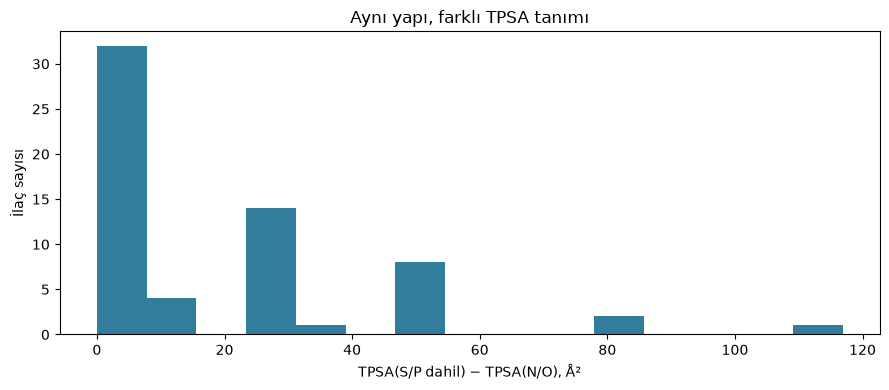

In [8]:
sp=read('tpsa_definition_sensitivity.csv');display(sp[sp.delta_S_P.astype(float)>0][['id','name','TPSA_N_O','TPSA_with_S_P','delta_S_P']])
fig,ax=plt.subplots(figsize=(9,4));ax.hist(sp.delta_S_P.astype(float),bins=15,color='#327d9b');ax.set(xlabel='TPSA(S/P dahil) − TPSA(N/O), Å²',ylabel='İlaç sayısı',title='Aynı yapı, farklı TPSA tanımı');plt.tight_layout();plt.savefig(FIG/'04_tpsa_definition.png',dpi=160);plt.show()

**Yorum:** Örneğin Ampicillin N/O-only TPSA yaklaşık 112,73; S/P katkısıyla yaklaşık 138,03 Å². Eski 138,0 değeriyle bu ikinci tanım daha yakın. Bu gözlem tüm eski farkların yalnız S/P kaynaklı olduğunu kanıtlamaz. Yeni varsayılanı sonuçlara bakarak ilaç bazında değiştirmiyoruz; her iki tanımı kaynaklı ayrı tabloda koruyoruz.

## 7. Üç gerçek antibakteriyelin tam 2D yapısı

2D çizimde çizgi uçları/köşeleri çoğunlukla karbon, karbonlara bağlı H'ler örtük gösterilir. Bu çizim kuralı atomları molekülden silmek değildir. Kama/kesik kama stereo yönelimini anlatır; 2D koordinatlar 3D konformasyon veya bağ enerjisi hesabı değildir.

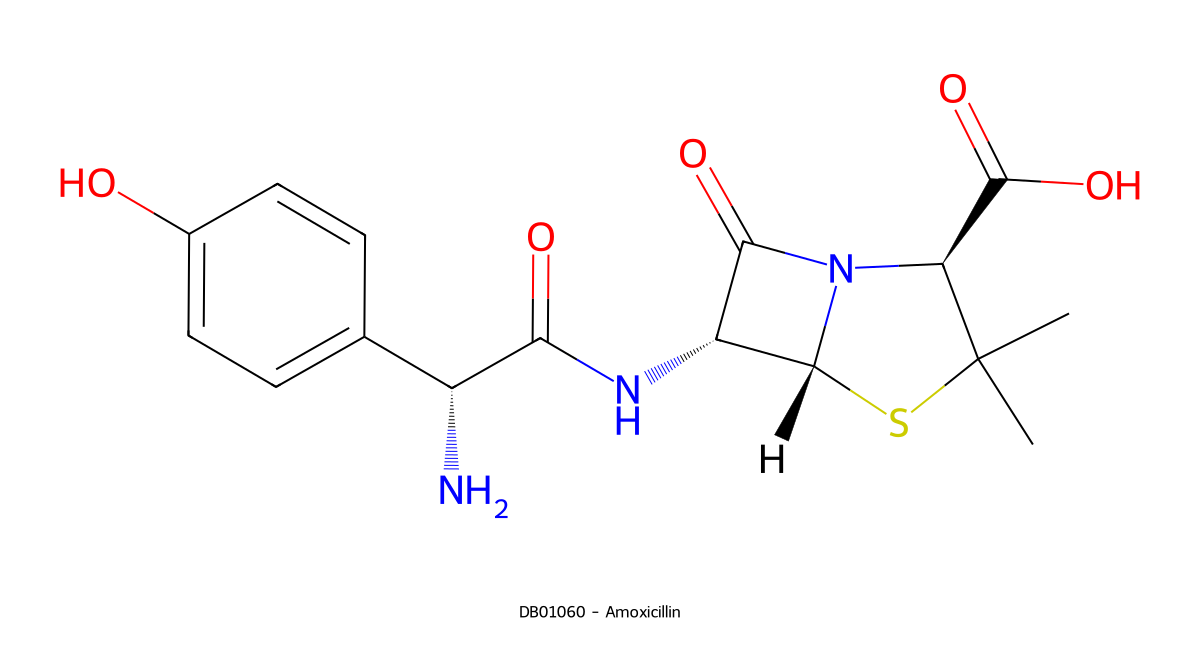

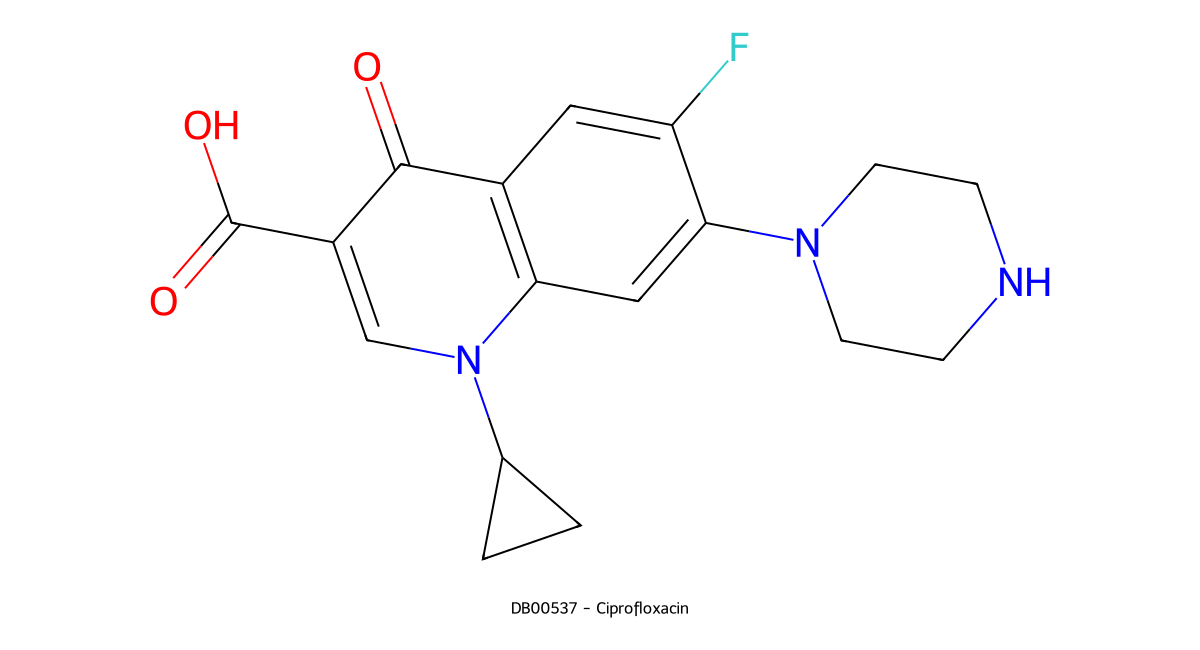

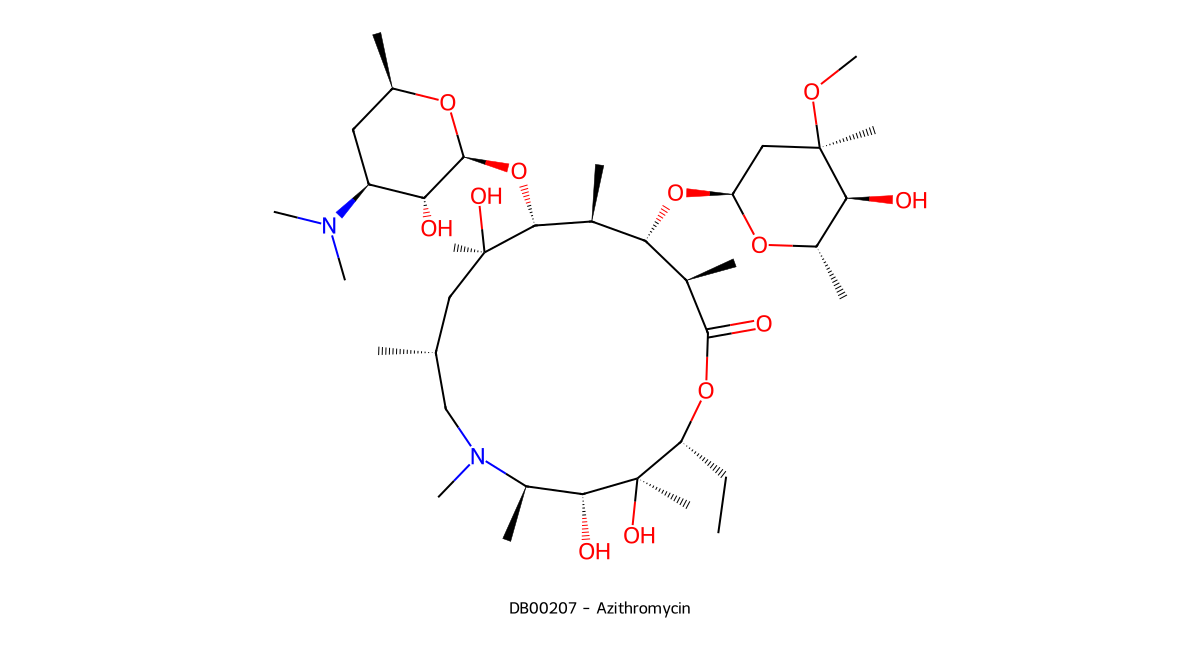

,id,name,formula,atom_count,bond_count,aromatic_atoms,chiral_assigned,MW,LogP,HBD,HBA,TPSA
0,DB00207,Azithromycin,C38H72N2O12,52,54,0,18,748.996,1.9007,5,14,180.08
1,DB00537,Ciprofloxacin,C17H18FN3O3,24,27,10,0,331.347,1.5833,2,4,74.57
2,DB01060,Amoxicillin,C16H19N3O5S,26,28,6,4,365.411,0.0237,4,6,132.96


In [9]:
examples=['DB01060','DB00537','DB00207']
for identifier in examples:
    name=sources.set_index('id').loc[identifier,'name'];mol=Chem.Mol(mols[identifier]);before=(mol.GetNumAtoms(),mol.GetNumBonds())
    image=Draw.MolToImage(mol,size=(1200,650),legend=f'{identifier} - {name}')
    image.save(FIG/(identifier+'_2D.png'));display(image)
    assert before==(mol.GetNumAtoms(),mol.GetNumBonds())
display(qc[qc.id.isin(examples)][['id','name','formula','atom_count','bond_count','aromatic_atoms','chiral_assigned']].merge(raw,on='id'))

**Yorum:** Amoxicillin'in beta-laktam halkası ve S içeren iskeleti, Ciprofloxacin'in aromatik/heterosiklik ve F içeren yapısı, Azithromycin'in büyük makrolid halkası ve şeker benzeri halkaları farklı atom/bağ düzenleri gösterir. Azithromycin daha büyük ve daha çok atom taşır; bu tek başına etkinlik ya da yan etki riski sıralaması değildir. Karşılaştırma moleküler temsil çeşitliliğini öğretir.

Karmaşık Vancomycin de aşağıda tam olarak çizilir. Daha küçük görünmesi için halka, şeker veya yan zincir çıkarılmadı.

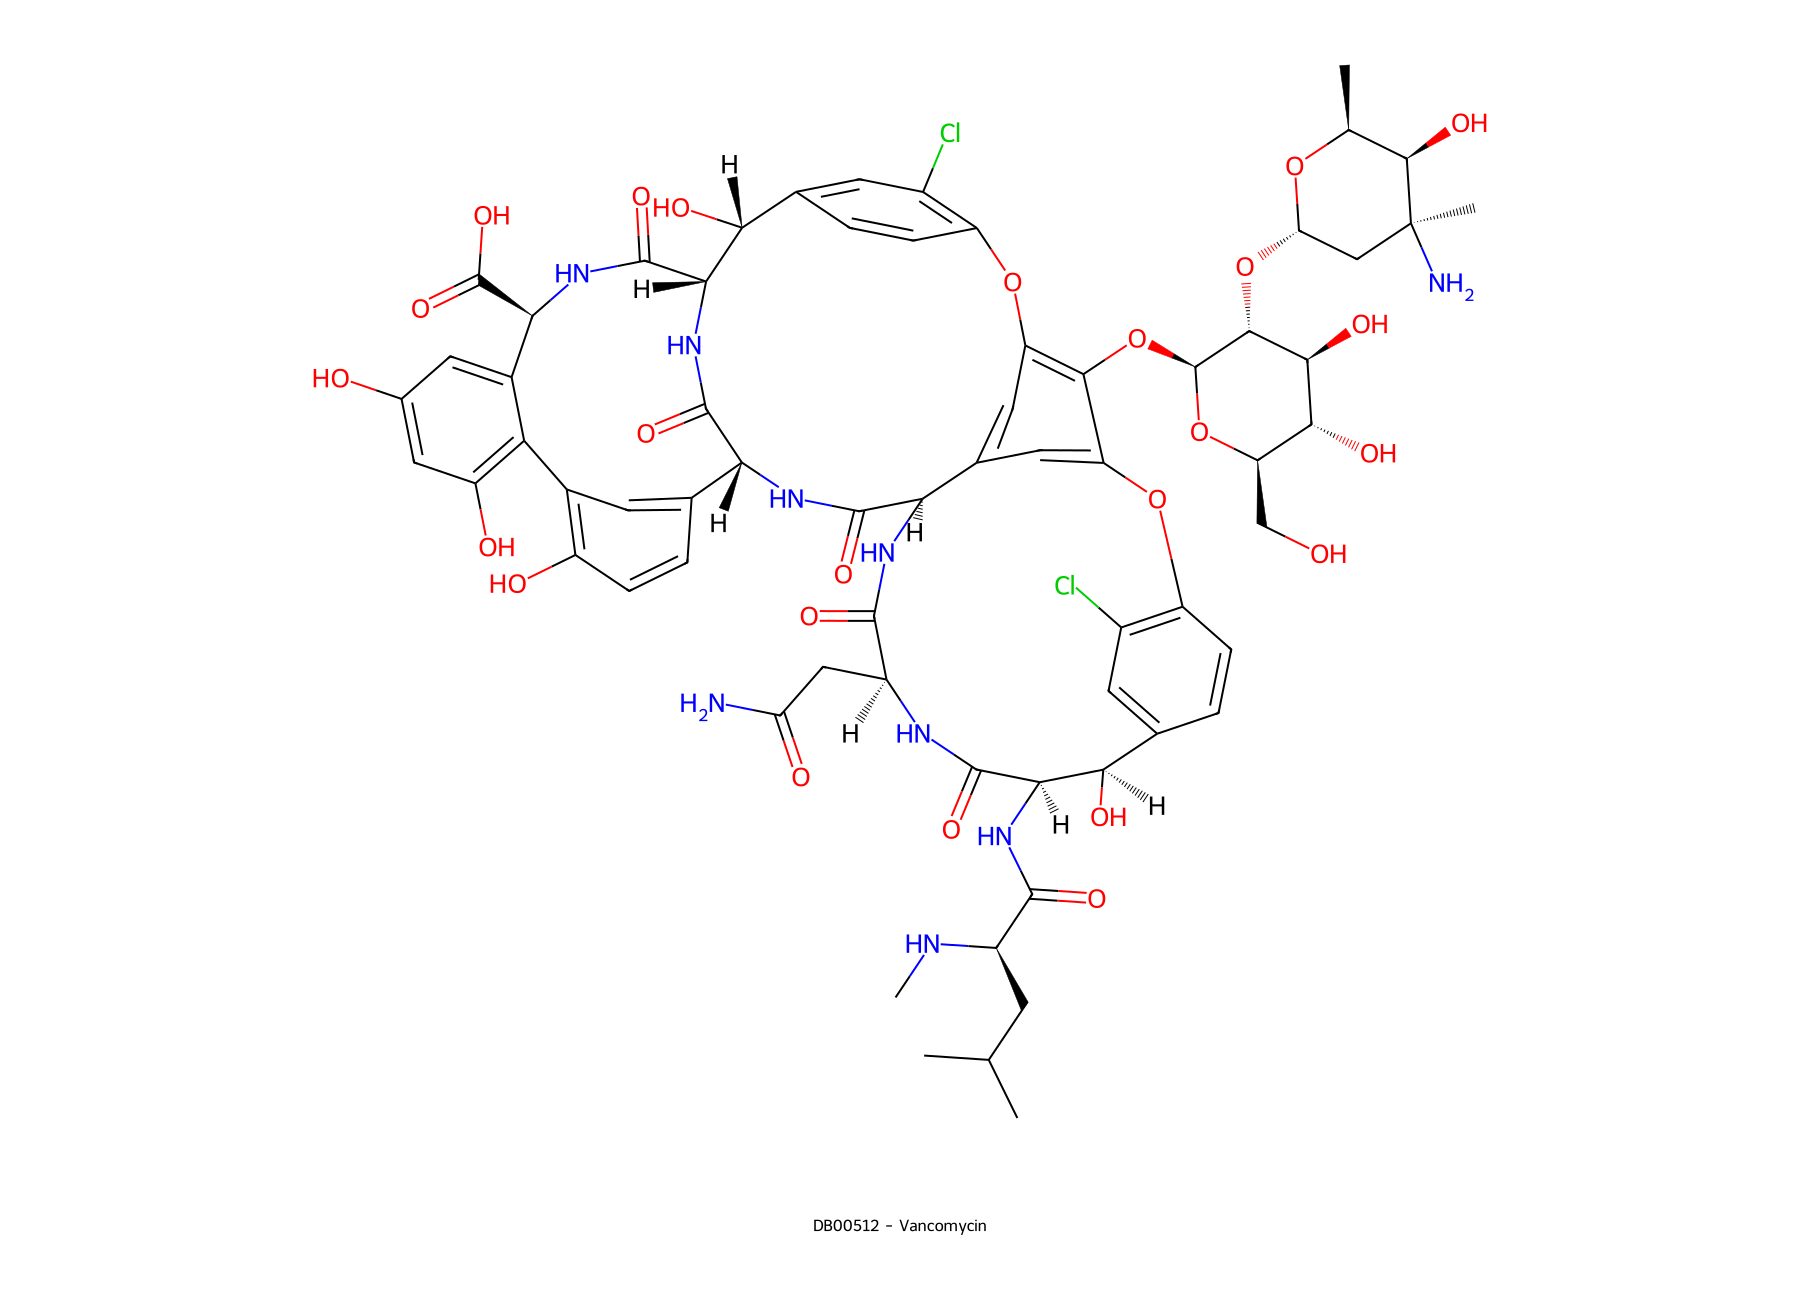

In [10]:
vm=Chem.Mol(mols['DB00512']);counts=(vm.GetNumAtoms(),vm.GetNumBonds());im=Draw.MolToImage(vm,size=(1800,1300),legend='DB00512 - Vancomycin');im.save(FIG/'05_vancomycin_full.png');display(im)
assert counts==(vm.GetNumAtoms(),vm.GetNumBonds())

**Yorum:** Vancomycin'in tam kaynak yapısındaki halkalar, şekerler ve yan zincirler korunur. Karmaşıklık, çizim boyutunu artırmayı gerektirir; atom/bağ silerek daha basit bir molekül oluşturulmaz. Çizimden hedef protein veya yan etki ilişkisi çıkarılmaz.

## 8. Atom ve bağ tablolarından öğretici molekül grafı

Linezolid örneğinde düğüm atom, kenar kovalent bağdır. Aromatiklik hem atom hem bağ özelliğidir; RDKit aromatik bağları `AROMATIC`/1,5 olarak temsil edebilir, bu ölçülmüş kesirli bağ mertebesi değildir. Atom `chiral_tag`'i yerel sıra kuralı, CIP etiketi R/S atamasıdır; birbirine doğrudan eşitlenmez. Eğitim tensörü, fingerprint veya embedding oluşturulmaz.

,atom_index,element,atomic_number,formal_charge,aromatic,degree,implicit_H,explicit_H_count,chiral_tag,CIP
0,0,C,6,0,False,1,3,0,CHI_UNSPECIFIED,
1,1,C,6,0,False,3,0,0,CHI_UNSPECIFIED,
2,2,O,8,0,False,1,0,0,CHI_UNSPECIFIED,
3,3,N,7,0,False,2,1,0,CHI_UNSPECIFIED,
4,4,C,6,0,False,2,2,0,CHI_UNSPECIFIED,
5,5,C,6,0,False,3,0,1,CHI_TETRAHEDRAL_CW,S
6,6,C,6,0,False,2,2,0,CHI_UNSPECIFIED,
7,7,N,7,0,False,3,0,0,CHI_UNSPECIFIED,
8,8,C,6,0,False,3,0,0,CHI_UNSPECIFIED,
9,9,O,8,0,False,1,0,0,CHI_UNSPECIFIED,


,bond_index,begin_atom,end_atom,bond_type,bond_order,aromatic,stereo,direction
0,0,0,1,SINGLE,1.0,False,STEREONONE,NONE
1,1,1,2,DOUBLE,2.0,False,STEREONONE,NONE
2,2,1,3,SINGLE,1.0,False,STEREONONE,NONE
3,3,3,4,SINGLE,1.0,False,STEREONONE,NONE
4,4,4,5,SINGLE,1.0,False,STEREONONE,NONE
5,5,5,6,SINGLE,1.0,False,STEREONONE,NONE
6,6,6,7,SINGLE,1.0,False,STEREONONE,NONE
7,7,7,8,SINGLE,1.0,False,STEREONONE,NONE
8,8,8,9,DOUBLE,2.0,False,STEREONONE,NONE
9,9,8,10,SINGLE,1.0,False,STEREONONE,NONE


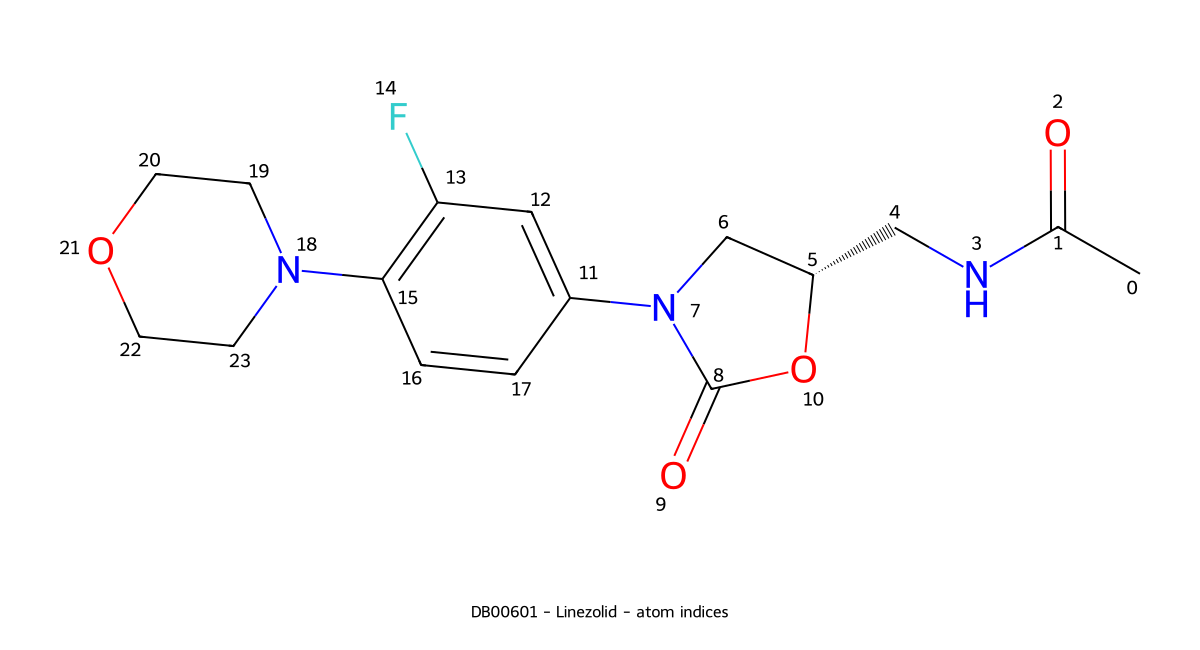

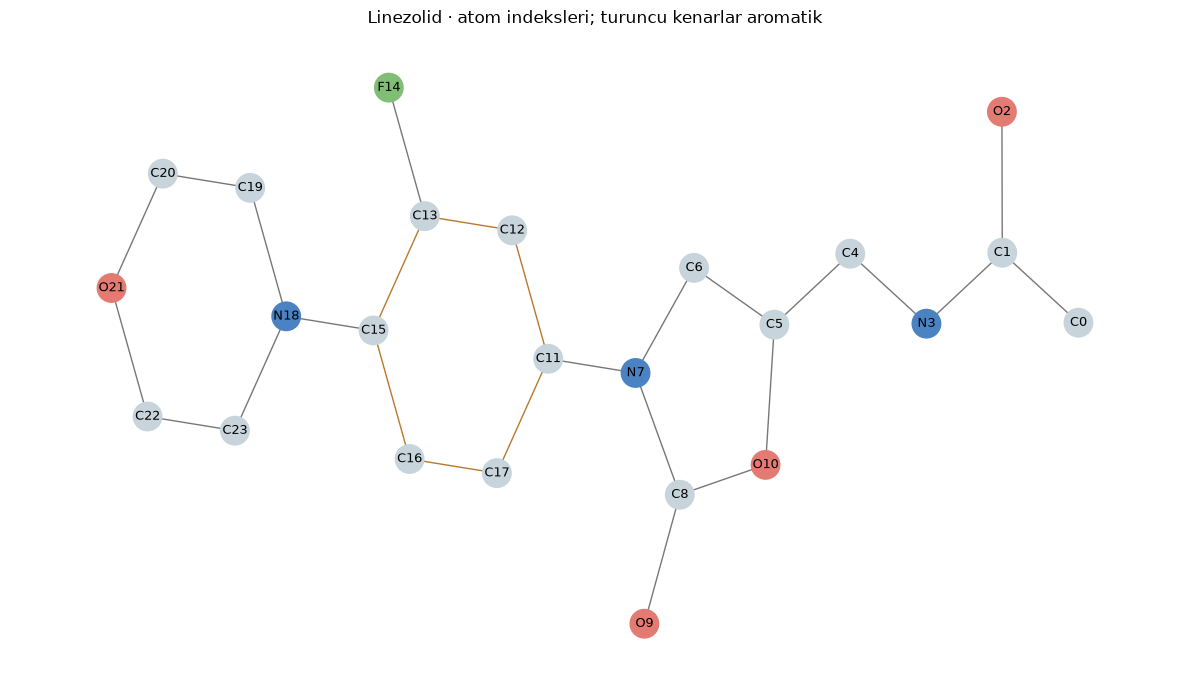

In [11]:
lm=Chem.Mol(mols['DB00601']);atoms,bonds=atom_bond_tables(lm)
display(pd.DataFrame(atoms));display(pd.DataFrame(bonds))
options=Draw.MolDrawOptions();options.addAtomIndices=True
indexed=Draw.MolToImage(lm,size=(1200,650),options=options,legend='DB00601 - Linezolid - atom indices')
indexed.save(FIG/'DB00601_indexed.png');display(indexed)
rdDepictor.Compute2DCoords(lm);conf=lm.GetConformer();graph=nx.Graph()
graph.add_nodes_from(range(lm.GetNumAtoms()));graph.add_edges_from((b.GetBeginAtomIdx(),b.GetEndAtomIdx()) for b in lm.GetBonds())
pos={i:(conf.GetAtomPosition(i).x,conf.GetAtomPosition(i).y) for i in graph}
colors={'C':'#c7d4dc','N':'#4b82c2','O':'#e47b73','F':'#80bd75'}
fig,ax=plt.subplots(figsize=(12,7));nx.draw_networkx_edges(graph,pos,ax=ax,edge_color=['#b9782c' if lm.GetBondBetweenAtoms(a,b).GetIsAromatic() else '#777777' for a,b in graph.edges])
nx.draw_networkx_nodes(graph,pos,ax=ax,node_size=420,node_color=[colors.get(lm.GetAtomWithIdx(i).GetSymbol(),'#bca4d5') for i in graph])
nx.draw_networkx_labels(graph,pos,ax=ax,labels={i:f'{lm.GetAtomWithIdx(i).GetSymbol()}{i}' for i in graph},font_size=9)
ax.set_title('Linezolid · atom indeksleri; turuncu kenarlar aromatik');ax.axis('off');plt.tight_layout();plt.savefig(FIG/'06_linezolid_teaching_graph.png',dpi=170);plt.show()
assert graph.number_of_nodes()==lm.GetNumAtoms() and graph.number_of_edges()==lm.GetNumBonds()

**Yorum:** Her atom/bağ tabloda ve grafikte aynı indeksle izlenebilir. Grafın 2D yerleşimi yalnız gösterimdir. Bağ tipi ve stereo ayrıntısı tablolarda bulunur; çizgi rengine indirgenmez. Hidrojenler kaynak SMILES/RDKit temsilindeki örtük/açık biçimleriyle korunur; bu bir drug–protein veya öğrenme grafı değildir.

## 9. Eksik kimya kayıtlarının geri kazanımı ve dağılımlar

Önceki 41 kimya kaydı ile eksik 21 kayıt aynı 62 kimlik üzerinden karşılaştırılır. “Ham hesap tamam” ve “temkinli QC'de bayraksız” ayrı sayılır; etiket varlığı/sıklığı kimya hesabına girmez.

,id,name,cid,parse_status,identity_verified_local,strict_qc_pass,review_flags,old_chemistry_available,newly_computed_raw,recovered_strict
10,DB00438,Ceftazidime,5481173,valid,True,True,,False,True,True
13,DB00479,Amikacin,37768,valid,True,True,,False,True,True
15,DB00493,Cefotaxime,5742673,valid,True,True,,False,True,True
17,DB00535,Cefdinir,6915944,valid,True,True,,False,True,True
20,DB00567,Cephalexin,27447,valid,True,True,,False,True,True
25,DB00671,Cefixime,5362065,valid,True,True,,False,True,True
29,DB00713,Oxacillin,6196,valid,True,True,,False,True,True
30,DB00779,Nalidixic acid,4421,valid,True,True,,False,True,True
31,DB00798,Gentamicin,3467,valid,True,False,multiple_components|unspecified_atom_stereo,False,True,False
43,DB01112,Cefuroxime,5479529,valid,True,True,,False,True,True


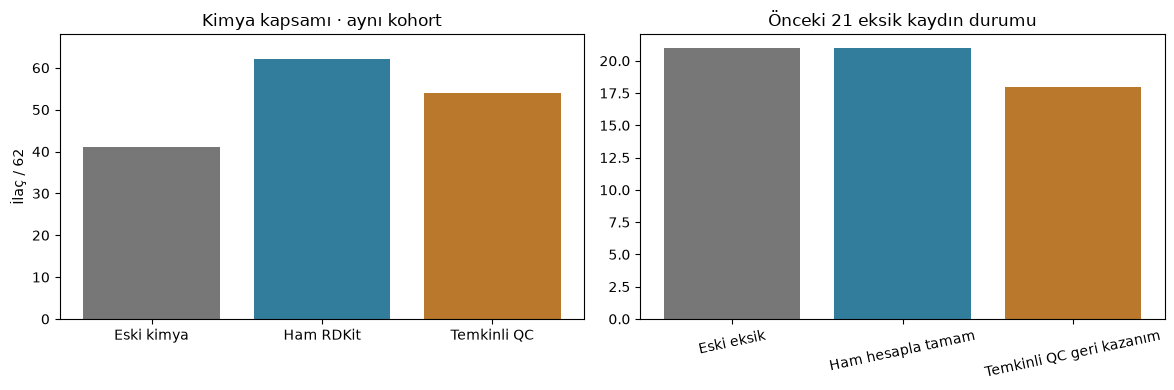

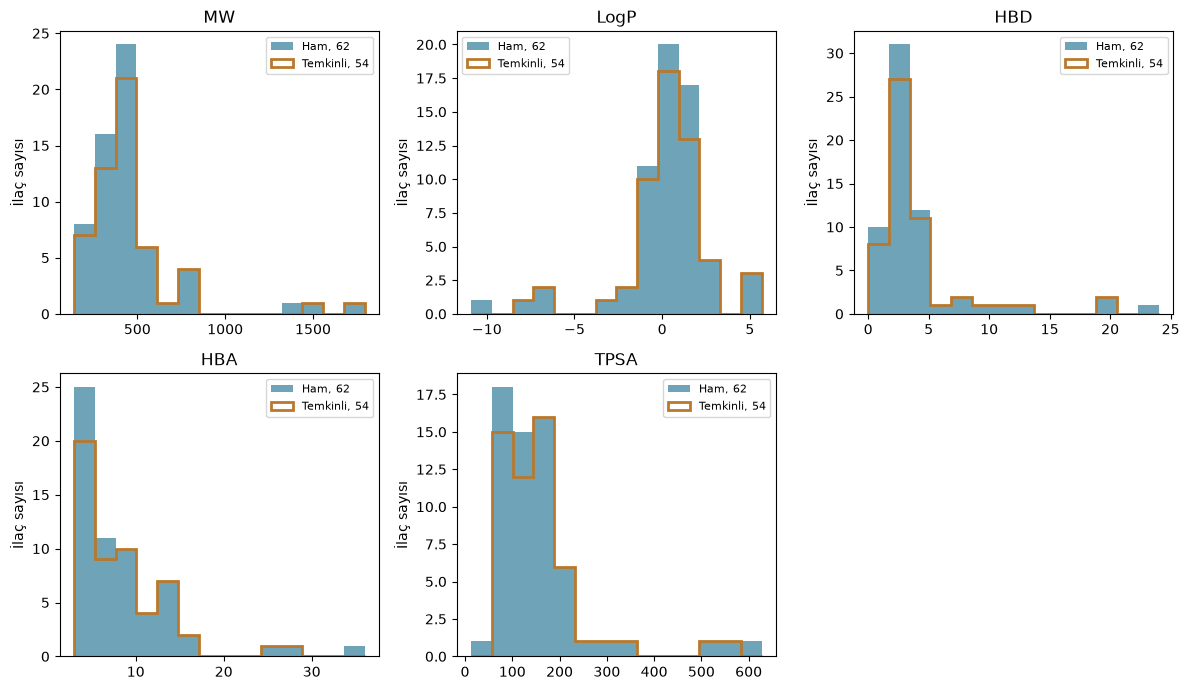

In [12]:
display(recovery[~recovery.old_chemistry_available.astype(bool)])
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].bar(['Eski kimya','Ham RDKit','Temkinli QC'],[41,62,54],color=['#777777','#327d9b','#b9782c']);axes[0].set_ylim(0,68);axes[0].set_ylabel('İlaç / 62');axes[0].set_title('Kimya kapsamı · aynı kohort')
axes[1].bar(['Eski eksik','Ham hesapla tamam','Temkinli QC geri kazanım'],[21,21,18],color=['#777777','#327d9b','#b9782c']);axes[1].tick_params(axis='x',labelrotation=12);axes[1].set_title('Önceki 21 eksik kaydın durumu')
plt.tight_layout();plt.savefig(FIG/'07_recovery.png',dpi=160);plt.show()
fig,axes=plt.subplots(2,3,figsize=(12,7))
for ax,k in zip(axes.flat,['MW','LogP','HBD','HBA','TPSA']):
    bins=np.histogram_bin_edges(raw[k],bins=14)
    ax.hist(raw[k],bins=bins,color='#327d9b',alpha=.7,label='Ham, 62');ax.hist(clean[k].dropna(),bins=bins,histtype='step',linewidth=2,color='#b9782c',label='Temkinli, 54');ax.set(title=k,ylabel='İlaç sayısı');ax.legend(fontsize=8)
axes.flat[-1].axis('off');plt.tight_layout();plt.savefig(FIG/'08_descriptor_distributions.png',dpi=160);plt.show()

**Yorum:** Önceki 21 eksik kaydın hepsinde yerel yapı üzerinden ham beş değer hesaplandı; 18'i temkinli incelemede bayraksız. Gentamicin, Cefprozil ve Methenamine incelemede kaldı. Dağılım farkında Gentamicin'in çok bileşenli toplam yapısı gibi kayıt tanımı etkileri vardır; uç değerler otomatik silinmedi. Temkinli QC 54, eski 41'e ekleme hesabı değildir: eski 41'in beşi de inceleme bayrağı taşıyor (36 eski + 18 geri kazanım = 54).

## 10. PubChem, sınırlar ve tekrar üretim

Üretim analiz istemcisiyle **0 PUG REST çağrısı** yapıldı; 62 yerel kayıt yeterliydi. API formatı incelenirken web aracıyla CID 12560 için tek keşif isteği denendi, araç erişilebilir veri döndürmedi; sonuçlar özellik hesabına girmedi. Bu başarısız deneme `pubchem_query_audit.json` içinde kayıtlı. Dokümanların bazı doğrudan sayfaları CAPTCHA döndürdü; resmi indeks açıklamaları ve erişilebilir RDKit dokümanları kullanıldı. Güncel PubChem yapı yanıtı doğrulandı iddiası yok.

`wp04_pubchem.py` gerektiğinde yalnız onaylı CID, en fazla 8 CID/istek, varsayılan ağ kapalı, toplam 3 istek bütçesi, en fazla 1 istek/saniye, CID yanıt kontrolü ve hash'li önbellek uygular. Canlı sorgu yapılmadan sentetik yanıtlarla test edilir. Eksik stereo veya karışım sorununu adla arayıp tek yapı seçerek gizlemez.

Önceki raporlar korunur. Nihai 30 kategori değişmez; negatif, split, ölçekleme, protein özelliği, GNN/tensör veya eğitim yok. WP04 sonunda kullanıcı onayı beklenir.

Kaynaklar: [RDKit başlangıç](https://rdkit.org/docs/GettingStartedInPython.html), [Crippen tanımı](https://rdkit.org/docs/source/rdkit.Chem.Crippen.html), [TPSA/stereo ayrıntısı](https://www.rdkit.org/docs/RDKit_Book.html), [PubChem PUG REST](https://pubchem.ncbi.nlm.nih.gov/docs/pug-rest).